# A7_P2_S1 outputs: Experiment 2 run used for Parts 2-4

This is `A7_P2_S1.ipynb` run once with **Experiment 2** in Cell 2 (48 / 2 / 1 / 192), stopped after Cell 14H. It is the run that saved the shared checkpoint `tiny_transformer.pt` used by `A7_P2_S2` and `A7_P2_S3`, and its numbers (final loss 0.1275, 229.38 s) are the **baseline and Experiment 2 rows** of the Part 1 table.

# PART 1: SETUP AND TRAINING DATA

In [1]:
#!pip install psutil
#%pip install pandas
#%pip install transformers

In [2]:
# ============================================================
# CELL 0: TRAINING PRESETS
# ============================================================
# Choose how long you want to train the model.
#
# quick:     Verify that the model works.
# classroom: Observe learning during class.
# extended:  Experiment with additional training.
# ============================================================

TRAINING_MODE = "classroom"

TRAINING_PRESETS = {
    "quick": 50,
    "classroom": 30000,
    "extended": 1000
}

TRAINING_STEPS = TRAINING_PRESETS[TRAINING_MODE]

print("Training mode:", TRAINING_MODE)
print("Training steps:", TRAINING_STEPS)

Training mode: classroom
Training steps: 30000


In [3]:
# ============================================================
# CELL 1: IMPORT LIBRARIES AND CONFIGURE THE ENVIRONMENT
# ============================================================
# Purpose:
# We are building a Transformer language model FROM SCRATCH.
#
# Unlike our earlier Hugging Face experiments, we will NOT use:
#   - AutoTokenizer.from_pretrained()
#   - AutoModelForCausalLM.from_pretrained()
#   - Pretrained model weights
#
# Instead, we will:
#   1. Create our own tokenizer.
#   2. Define our own neural network architecture.
#   3. Initialize model parameters randomly.
#   4. Train the parameters using text.
#   5. Generate new text using the trained model.
#
# PyTorch provides:
#   - Tensors and numerical operations
#   - Neural network layers
#   - Automatic differentiation (backpropagation)
#   - Optimization algorithms
#
# We use CPU by default so students with M1 Macs, Intel Macs,
# and Windows laptops can run the same notebook.
# ============================================================

import math
import random
import time
import platform
import psutil

import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from transformers import AutoConfig, AutoTokenizer, AutoModelForCausalLM

# Reproducibility: initialize random-number generators.
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

# Keep execution predictable on student laptops.
torch.set_num_threads(2)

DEVICE = torch.device("cpu")

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

PyTorch: 2.2.2
Device: cpu


In [4]:
# ============================================================
# CELL 2: CONFIGURE THE TRANSFORMER ARCHITECTURE
# ============================================================
# Purpose:
# Define the size and training settings of our language model.
#
# VOCAB_SIZE:
#   Number of unique characters in our training corpus.
#   We will calculate this automatically in a later cell.
#
# EMBEDDING_DIM:
#   Number of numerical features used to represent each token.
#
# NUM_HEADS:
#   Number of attention heads in each Transformer block.
#
# NUM_LAYERS:
#   Number of Transformer blocks stacked together.
#
# FEEDFORWARD_DIM:
#   Hidden dimension of the feed-forward neural network.
#
# CONTEXT_LENGTH:
#   Maximum number of tokens the model can examine at once.
#
# BATCH_SIZE:
#   Number of training sequences processed together.
#
# TRAINING_STEPS:
#   Number of parameter-update iterations.
# ============================================================

BATCH_SIZE = 16          # First used: Cell 6B
CONTEXT_LENGTH = 32

# Cell 2
EMBEDDING_DIM = 48       # First used: Cell 7A

# Cell 2: Configurations
NUM_HEADS = 2
NUM_LAYERS = 1
FEEDFORWARD_DIM = 192


# Cell 2
LEARNING_RATE = 0.001

# Embedding dimension must be divisible by attention heads.
assert EMBEDDING_DIM % NUM_HEADS == 0

HEAD_DIM = EMBEDDING_DIM // NUM_HEADS

print("Embedding dimension:", EMBEDDING_DIM)
print("Attention heads:", NUM_HEADS)
print("Dimension per head:", HEAD_DIM)       #24
print("Transformer blocks:", NUM_LAYERS)
print("Context length:", CONTEXT_LENGTH)

Embedding dimension: 48
Attention heads: 2
Dimension per head: 24
Transformer blocks: 1
Context length: 32


# PART 2: TOKENIZATION

In [5]:
# ============================================================
# CELL 3: CREATE OR LOAD TRAINING DATA
# ============================================================
# Purpose:
# Language models learn statistical patterns from text.
#
# During training, the model repeatedly sees sequences and
# attempts to predict the next character.
#
# For example:
#
# INPUT:  "student"
# TARGET: "tudents"
#
# We will use a small fictional corpus related to INFO 490.
#
# IMPORTANT:
# Repeating a small dataset helps demonstrate learning, but
# it does NOT create the linguistic knowledge of a real LLM.
#
# Students can replace training_corpus.txt with their own
# plain-text dataset before running this cell.
# ============================================================

CORPUS_PATH = Path("training_corpus.txt")  # Relative to the kernel working directory.

if not CORPUS_PATH.exists():
    sentences = [                                               # hypothetical character count
        "students build django applications.",                  # 32 characters, Batch-1
        "students learn python programming.",                   # 32 characters, Batch-2
        "students develop artificial intelligence systems.",    # 32 characters, Batch-3
        "language models predict the next token.",              # 32 characters, Batch-4.....
        "transformers use attention mechanisms.",
        "neural networks learn from training data.",
        "machine learning models contain parameters.",
        "the professor teaches artificial intelligence.",
        "students create innovative startup applications.",
        "django applications use models and views.",
        "training changes the weights of a neural network.",
        "inference uses previously learned parameters.",
        "the university offers courses in informatics.",
        "students experiment with language models.",
        "artificial intelligence can generate text.",
        "the model predicts characters using probabilities.",
        "attention helps models use contextual information.",
        "python is useful for machine learning research.",
        "the students are building useful software products.",
        "small language models can run on local computers."
    ]

    text = "\n".join(sentences)
    CORPUS_PATH.write_text((text + "\n") * 100, encoding="utf-8")

text = CORPUS_PATH.read_text(encoding="utf-8")

print("Characters in corpus:", len(text))
print("\nSample:\n")
print(text[:500])

Characters in corpus: 90300

Sample:

students build django applications.
students learn python programming.
students develop artificial intelligence systems.
language models predict the next token.
transformers use attention mechanisms.
neural networks learn from training data.
machine learning models contain parameters.
the professor teaches artificial intelligence.
students create innovative startup applications.
django applications use models and views.
training changes the weights of a neural network.
inference uses previously 


In [6]:
# ============================================================
# CELL 4: BUILD OUR OWN TOKENIZER
# ============================================================
# Purpose:
# Computers cannot directly perform neural-network operations
# on strings such as "students build django".
#
# We must convert text into numerical token IDs.
#
# Modern LLMs commonly use subword tokenizers.
# For simplicity, our model uses CHARACTER-LEVEL tokenization.
#
# Example:
#
# "cat" → ["c", "a", "t"] → [3, 1, 20]
#
# We create two dictionaries:
#
# stoi = string to integer
# itos = integer to string
#
# These allow encoding and decoding.
# ============================================================

chars = sorted(set(text))
VOCAB_SIZE = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}

sample = "students"

def encode(s):
    """Convert a string into a list of character token IDs."""
    return [stoi[ch] for ch in s]

def decode(ids):
    """Convert character token IDs back into a string."""
    return "".join(itos[int(i)] for i in ids)


print("Vocabulary size:", VOCAB_SIZE)
print("Original:", sample)
print("Encoded:", encode(sample))
print("Decoded:", decode(encode(sample)))

Vocabulary size: 27
Original: students
Encoded: [20, 21, 22, 6, 7, 16, 21, 20]
Decoded: students


In [7]:
# ============================================================
# CELL 5A: CONVERT TRAINING TEXT INTO PYTORCH TENSORS
# ============================================================
# Purpose:
# Convert the entire corpus into a sequence of token IDs.
#
# A tensor is a multidimensional numerical data structure.
#
# Here, our data is initially a one-dimensional tensor:
#
# [12, 4, 7, 2, 9, ...]
#
# Each number represents one character in the corpus.
#
# We also divide the corpus into training and validation sets.
# Training data updates the weights.
# Validation data evaluates performance on held-out sequences.
# ============================================================

data = torch.tensor(encode(text), dtype=torch.long)

split = int(0.9 * len(data))

train_data = data[:split]
val_data = data[split:]

print("Tensor shape:", data.shape)
print("Training tokens:", len(train_data))
print("Validation tokens:", len(val_data))
print("First 20 token IDs:", data[:20])

Tensor shape: torch.Size([90300])
Training tokens: 81270
Validation tokens: 9030
First 20 token IDs: tensor([20, 21, 22,  6,  7, 16, 21, 20,  1,  4, 22, 11, 14,  6,  1,  6, 12,  3,
        16,  9])


In [8]:
# ============================================================
# CELL 5B: NUMPY CPU VS. PYTORCH GPU PERFORMANCE (Tutorial)
# ============================================================
# Purpose:
# Compare numerical computation on CPU vs. GPU.
#
# NumPy:
#   Performs matrix multiplication on the CPU.
#
# PyTorch:
#   Can perform matrix multiplication on the GPU.
#
# Apple Silicon:
#   MPS = Metal Performance Shaders (Apple GPU).
#
# EXPERIMENT:
#   1. Create matrices of different sizes.
#   2. Perform the same calculation using NumPy and PyTorch.
#   3. Measure execution time.
#   4. Compare CPU vs. GPU performance.
#
# IMPORTANT:
# GPUs are not always faster for small calculations.
# ============================================================

# Select Apple GPU if available.
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"

results = []

for size in [100, 500, 1000, 2000]:

    # Create identical matrices for both libraries.
    A = np.random.rand(size, size).astype(np.float32)
    B = np.random.rand(size, size).astype(np.float32)

    A_gpu = torch.from_numpy(A).to(DEVICE)
    B_gpu = torch.from_numpy(B).to(DEVICE)

    # Warm up the GPU before measuring.
    for _ in range(3):
        _ = A_gpu @ B_gpu

    if DEVICE == "mps":
        torch.mps.synchronize()

    # NumPy CPU calculation.
    start = time.perf_counter()
    numpy_result = A @ B
    cpu_time = time.perf_counter() - start

    # PyTorch GPU calculation.
    start = time.perf_counter()
    torch_result = A_gpu @ B_gpu

    if DEVICE == "mps":
        torch.mps.synchronize()

    gpu_time = time.perf_counter() - start

    results.append({
        "Matrix Size": f"{size} × {size}",
        "NumPy CPU (ms)": round(cpu_time * 1000, 2),
        "PyTorch GPU (ms)": round(gpu_time * 1000, 2),
        "GPU Speedup": round(cpu_time / gpu_time, 2)
    })

# Display comparison.
results_df = pd.DataFrame(results)

print("DEVICE:", DEVICE.upper())
print("\nCPU VS. GPU PERFORMANCE")
display(results_df)

DEVICE: MPS

CPU VS. GPU PERFORMANCE


,Matrix Size,NumPy CPU (ms),PyTorch GPU (ms),GPU Speedup
0,100 × 100,1.19,0.46,2.59
1,500 × 500,2.00,1.03,1.94
2,1000 × 1000,11.43,2.46,4.65
3,2000 × 2000,79.92,15.00,5.33


In [9]:
# ============================================================
# CELL 6A: CREATE INPUT AND TARGET SEQUENCES (Tutorial)
# ============================================================
# Purpose:
# A causal language model learns to predict the NEXT token.
#
# We train it using two sequences:
#
# INPUT:  characters 0 through N-1
# TARGET: characters 1 through N
#
# The target sequence is shifted one position forward.
#
# Example:
#
# INPUT:  "studen"
# TARGET: "tudent"
#
# At each position, the model predicts the following character.
# ============================================================

sample = train_data[:CONTEXT_LENGTH + 1]

x = sample[:-1]
y = sample[1:]

print("INPUT TEXT: ", decode(x))
print("TARGET TEXT:", decode(y))

print("\nINPUT IDs:", x.tolist())
print("TARGET IDs:", y.tolist())

INPUT TEXT:  students build django applicatio
TARGET TEXT: tudents build django application

INPUT IDs: [20, 21, 22, 6, 7, 16, 21, 20, 1, 4, 22, 11, 14, 6, 1, 6, 12, 3, 16, 9, 17, 1, 3, 18, 18, 14, 11, 5, 3, 21, 11, 17]
TARGET IDs: [21, 22, 6, 7, 16, 21, 20, 1, 4, 22, 11, 14, 6, 1, 6, 12, 3, 16, 9, 17, 1, 3, 18, 18, 14, 11, 5, 3, 21, 11, 17, 16]


In [10]:
# ============================================================
# CELL 6B: CREATE MINI-BATCHES FOR TRAINING (Create Function + Test it)
# ============================================================
# Purpose:
# Training does not require processing the entire corpus
# simultaneously.
#
# Instead, we randomly select small batches of sequences.
#
# WHY MINI-BATCHES?
#
# 1. MEMORY:
#    Processing smaller sequences requires less memory.
#
# 2. COMPUTATION:
#    Shorter sequences reduce attention computation.
#
# 3. LEARNING:
#    The model can update its weights after each mini-batch.
#
# 4. RANDOM SAMPLING:
#    Different batches expose the model to different
#    portions of the training corpus.
#
# OUR CONFIGURATION:
#    Training Corpus = 81,270 tokens
#    Batch Size       = 16 sequences
#    Context Length   = 32 tokens
#
#    Input Shape = (16, 32)
#
# IMPORTANT:
#    We are NOT discarding the remaining training data.
#    It remains available for sampling in future steps.
#
#    Random sampling does not guarantee that every
#    training example will be visited exactly once.
#
# Instead, we randomly select short sequences.
#
# Each batch contains:
#
# BATCH_SIZE sequences
# CONTEXT_LENGTH tokens per sequence
#
# Tensor shape:
#
# (batch_size, context_length)
#
# For our configuration:
#
# (16, 32)
# ============================================================

def get_batch(source):
    """Sample random input/target sequences from a token tensor."""
    starts = torch.randint(0, len(source) - CONTEXT_LENGTH, (BATCH_SIZE,))
    x = torch.stack([source[i:i + CONTEXT_LENGTH] for i in starts])
    y = torch.stack([source[i + 1:i + CONTEXT_LENGTH + 1] for i in starts])
    return x.to(DEVICE), y.to(DEVICE)

xb, yb = get_batch(train_data)

print("Input batch shape:", xb.shape)
print("Target batch shape:", yb.shape)
print("\nFirst input:", decode(xb[0]))
print("First target:", decode(yb[0]))

Input batch shape: torch.Size([16, 32])
Target batch shape: torch.Size([16, 32])



First input: tics.
students experiment with l
First target: ics.
students experiment with la


# PART 3: EMBEDDINGS AND PARAMETERS

In [11]:
# ============================================================
# CELL 7A: UNDERSTANDING TOKEN EMBEDDINGS (Creating Object "token_embedding" from Class nm.Embedding in line 30 + Testing it)
# ============================================================
# Purpose:
# Token IDs are arbitrary numerical labels.
#
# For example:
#   "a" might have ID 3.
#   "b" might have ID 4.
#
# These numbers do NOT mean that "b" is mathematically
# greater than "a".
#
# An embedding layer maps each token ID to a learned vector.
#
# Example:
#
# Token ID 3 → [0.12, -0.54, 0.87, ...]
#
# Embedding shape:
#
# (vocabulary_size, embedding_dimension)
#
# Number of parameters:
#
# vocabulary_size × embedding_dimension
# ============================================================

# Cell 7A: Initiating the class
token_embedding = nn.Embedding(VOCAB_SIZE, EMBEDDING_DIM)

# Testing
sample_ids = torch.tensor(encode("student"))
sample_embeddings = token_embedding(sample_ids)

print("Input token IDs:", sample_ids)
print("Embedding shape:", sample_embeddings.shape)

print("Embedding vector for first token:\n", sample_embeddings[0])

print("\nCalculated parameters:", VOCAB_SIZE * EMBEDDING_DIM)
print("Actual parameters:", sum(p.numel() for p in token_embedding.parameters()))

Input token IDs: tensor([20, 21, 22,  6,  7, 16, 21])
Embedding shape: torch.Size([7, 48])
Embedding vector for first token:
 tensor([ 0.8521, -1.6947,  1.1806, -2.8929, -0.3876, -0.7124, -1.6171, -0.3590,
         0.0514,  0.6950,  1.8352, -1.9180, -1.3924,  0.5405,  0.4351, -2.2717,
        -0.1339, -0.0586,  0.1257, -0.5526,  0.0745, -0.1493, -0.5523, -0.0934,
        -1.0284,  0.4044,  2.1426, -0.5154,  1.0827,  1.2499,  0.9821,  0.2269,
         0.4928, -0.5128,  0.3006,  0.0773,  0.6478, -0.4324,  1.1740,  0.7011,
         0.6674, -0.8036, -1.3776, -0.4410,  0.1418,  1.1085,  0.5544,  1.5818],
       grad_fn=<SelectBackward0>)

Calculated parameters: 1296
Actual parameters: 1296


In [12]:
# ============================================================
# CELL 7B: UNDERSTANDING POSITIONAL EMBEDDINGS
# ============================================================
# Purpose:
# Token embeddings represent token identities.
#
# But the same character can appear at different positions.
#
# Example:
#
# "cat" and "tac" contain the same characters but in
# different orders.
#
# Positional embeddings provide information about WHERE
# each token appears in the sequence.
#
# Our model uses learned positional embeddings.
#
# Number of parameters:
#
# context_length × embedding_dimension
# ============================================================

position_embedding = nn.Embedding(CONTEXT_LENGTH, EMBEDDING_DIM)

positions = torch.arange(CONTEXT_LENGTH)

# Retrieve vectors for requested position ids (can be one or many)
position_vectors = position_embedding(positions)

print("Position IDs:", positions)
print("Position embedding shape:", position_vectors.shape)

print("\nCalculated parameters:", CONTEXT_LENGTH * EMBEDDING_DIM)
print("Actual parameters:", sum(p.numel() for p in position_embedding.parameters()))

Position IDs: tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])
Position embedding shape: torch.Size([32, 48])

Calculated parameters: 1536
Actual parameters: 1536


# PART 4: ATTENTION

In [13]:
# ============================================================
# CELL 8A: INTRODUCING QUERY, KEY, AND VALUE PROJECTIONS
# ============================================================
# Purpose:
# Self-attention allows token representations to incorporate
# information from other positions in the sequence.
#
# The model creates three representations:
#
# Query (Q): What information is this position looking for?
# Key (K):   What information can this position match against?
# Value (V): What information can this position contribute?
#
# These are LEARNED linear transformations.
#
# For a simple demonstration, we create three linear layers.
# ============================================================

query_layer = nn.Linear(EMBEDDING_DIM, EMBEDDING_DIM)
key_layer = nn.Linear(EMBEDDING_DIM, EMBEDDING_DIM)
value_layer = nn.Linear(EMBEDDING_DIM, EMBEDDING_DIM)

# sample_ids = student (7 characters -> Represented as 48 numbers per character -> (7,48))
sample_vectors = token_embedding(sample_ids)
Q = query_layer(sample_vectors)
K = key_layer(sample_vectors)
V = value_layer(sample_vectors)

print("Input shape:", sample_vectors.shape)
print("Query shape:", Q.shape)
print("Key shape:", K.shape)
print("Value shape:", V.shape)


print("\n\nWq shape:", query_layer.weight.shape)
print("bq shape:", query_layer.bias.shape)
# Query weight matrix
print(query_layer.weight)

# Query bias vector
print(query_layer.bias)

Input shape: torch.Size([7, 48])
Query shape: torch.Size([7, 48])
Key shape: torch.Size([7, 48])
Value shape: torch.Size([7, 48])


Wq shape: torch.Size([48, 48])
bq shape: torch.Size([48])
Parameter containing:
tensor([[ 0.0223,  0.1021, -0.1240,  ..., -0.0353,  0.0166,  0.0085],
        [ 0.0927,  0.0924,  0.1188,  ...,  0.1165, -0.1319,  0.1247],
        [ 0.1155,  0.0089, -0.0116,  ..., -0.1092, -0.1263, -0.0002],
        ...,
        [-0.0515, -0.1422,  0.1362,  ..., -0.0531, -0.1135, -0.1129],
        [-0.0667,  0.0230, -0.0167,  ...,  0.0223, -0.0244,  0.0909],
        [ 0.1178,  0.0642,  0.0312,  ...,  0.0113,  0.1333, -0.1056]],
       requires_grad=True)
Parameter containing:
tensor([ 0.0344,  0.0344, -0.0017,  0.1284,  0.0290,  0.0078,  0.0985, -0.0114,
        -0.0093, -0.1190, -0.0009, -0.0674,  0.0836,  0.1256, -0.1347, -0.0836,
         0.1390, -0.0616,  0.1284,  0.1421, -0.0362, -0.1168,  0.0722,  0.0656,
         0.1254,  0.0208,  0.0785, -0.1238,  0.0199,  0.0340,  0.

In [14]:
# ============================================================
# CELL 8B: CALCULATE SELF-ATTENTION SCORES
# ============================================================
# Purpose:
# Attention uses similarity between Query and Key vectors.
#
# The fundamental operation is:
#
# Q × K-transpose
#
# The result contains a score for every pair of positions.
#
# We divide by sqrt(embedding_dimension) to scale the scores.
#
# This is a single-head demonstration.
# The complete Transformer will use multi-head attention.
# ============================================================

# @ represents matrix multiplication
scores = Q @ K.T / math.sqrt(EMBEDDING_DIM)

print("Attention score matrix shape:", scores.shape)
print("\nAttention scores:\n", scores)

Attention score matrix shape: torch.Size([7, 7])

Attention scores:
 tensor([[ 0.5306, -0.0649, -0.1249, -0.0510, -0.2270,  0.0567, -0.0649],
        [-0.0142, -0.6923, -0.3525,  0.1558,  0.3857, -0.4634, -0.6923],
        [ 0.0608,  0.1992, -0.0254, -0.0443, -0.1601,  0.1567,  0.1992],
        [ 0.2155,  0.0061, -0.5648,  0.4164,  0.1114,  0.1733,  0.0061],
        [ 0.1170, -0.2669, -0.0236,  0.1549, -0.4730,  0.2511, -0.2669],
        [-0.1832, -0.7954, -0.1152,  0.2770, -0.2662,  0.1885, -0.7954],
        [-0.0142, -0.6923, -0.3525,  0.1558,  0.3857, -0.4634, -0.6923]],
       grad_fn=<DivBackward0>)


In [15]:
# ============================================================
# CELL 8C: APPLY CAUSAL ATTENTION MASKING
# ============================================================
# Purpose:
# Our language model predicts the NEXT character.
#
# During prediction, a position must not access future tokens.
#
# Otherwise, the model could cheat during training.
#
# A causal mask allows each position to attend only to:
#   - itself
#   - earlier positions
#
# Future positions receive negative infinity before softmax.
#
# Softmax then assigns those positions probability zero.
# ============================================================

T = scores.shape[0]

# STEP 1: Create causal mask.
# 1 = Allowed, 0 = Blocked.
causal_mask = torch.tril(torch.ones(T, T, dtype=torch.bool))

# STEP 2: Replace future attention scores with -inf.
masked_scores = scores.masked_fill(~causal_mask, float("-inf"))

# STEP 3: Apply Softmax.
# -inf becomes 0 probability.
# Remaining probabilities sum to 1.
attention_weights = F.softmax(masked_scores, dim=-1)

# STEP 4: Display results.
print("CAUSAL MASK:\n", causal_mask.int())
print("\nORIGINAL ATTENTION SCORES:\n", scores)
print("\nMASKED SCORES (BEFORE SOFTMAX):\n", masked_scores)
print("\nATTENTION PROBABILITIES (AFTER SOFTMAX):\n", attention_weights)
print("\nROW SUMS:", attention_weights.sum(dim=-1))

CAUSAL MASK:
 tensor([[1, 0, 0, 0, 0, 0, 0],
        [1, 1, 0, 0, 0, 0, 0],
        [1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1, 1]], dtype=torch.int32)

ORIGINAL ATTENTION SCORES:
 tensor([[ 0.5306, -0.0649, -0.1249, -0.0510, -0.2270,  0.0567, -0.0649],
        [-0.0142, -0.6923, -0.3525,  0.1558,  0.3857, -0.4634, -0.6923],
        [ 0.0608,  0.1992, -0.0254, -0.0443, -0.1601,  0.1567,  0.1992],
        [ 0.2155,  0.0061, -0.5648,  0.4164,  0.1114,  0.1733,  0.0061],
        [ 0.1170, -0.2669, -0.0236,  0.1549, -0.4730,  0.2511, -0.2669],
        [-0.1832, -0.7954, -0.1152,  0.2770, -0.2662,  0.1885, -0.7954],
        [-0.0142, -0.6923, -0.3525,  0.1558,  0.3857, -0.4634, -0.6923]],
       grad_fn=<DivBackward0>)

MASKED SCORES (BEFORE SOFTMAX):
 tensor([[ 0.5306,    -inf,    -inf,    -inf,    -inf,    -inf,    -inf],
        [-0.0142, -0.6923,    -inf,    -inf,    -inf,    -inf,    -inf

# PART 5: BUILD THE TRANSFORMER

In [16]:
# ============================================================
# CELL 9A: BUILD A TRANSFORMER BLOCK
# ============================================================
# Purpose:
# A Transformer block combines:
#
# 1. Multi-head self-attention
# 2. Residual connections
# 3. Layer normalization
# 4. Feed-forward neural network
#
# Multi-head attention allows the model to learn different
# attention patterns simultaneously.
#
# Residual connections help information and gradients flow
# through the network.
#
# Layer normalization stabilizes representations.
#
# The feed-forward network transforms each token's features.
#
# PyTorch provides MultiheadAttention, which implements
# the Q/K/V projections and attention computation.
#
# We use batch_first=True:
# (batch, sequence, embedding_dimension)
# ============================================================

class TransformerBlock(nn.Module):

    def __init__(self, embedding_dim, num_heads, feedforward_dim):
        super().__init__()

        # Main Component 1
        self.attention = nn.MultiheadAttention(
            embed_dim=embedding_dim,
            num_heads=num_heads,
            dropout=0.0,
            batch_first=True)

        # Supporting Component 1
        self.ln1 = nn.LayerNorm(embedding_dim)
        self.ln2 = nn.LayerNorm(embedding_dim)

        # Main Component 2
        self.feedforward = nn.Sequential(
            nn.Linear(embedding_dim, feedforward_dim),
            nn.ReLU(),
            nn.Linear(feedforward_dim, embedding_dim))


    def forward(self, x):

        T = x.shape[1]


        # True means a position is blocked from attention.
        mask = torch.triu(torch.ones(T, T, device=x.device, dtype=torch.bool), diagonal=1)

        # Supporting Component 2
        # Attention + residual connection.
        normalized = self.ln1(x)
        attended, _ = self.attention(normalized, normalized, normalized, attn_mask=mask, need_weights=False)

        # Residual 1: Original representation + attention output
        x = x + attended

        # Residual 2: Updated representation + feed-forward output
        # Feed-forward network + residual connection.
        x = x + self.feedforward(self.ln2(x))

        return x

In [17]:
# ============================================================
# CELL 9B: BUILDING OUR COMPLETE TINY TRANSFORMER
# ============================================================
# Purpose:
# Combine all the components into one language model.
#
# Architecture:
#
# Token IDs
#    ↓
# Token Embeddings + Position Embeddings
#    ↓
# Transformer Block(s)
#    ↓
# Layer Normalization
#    ↓
# Linear Output Layer
#    ↓
# Logits for every vocabulary token
#
# The output tensor has shape:
#
# (batch_size, sequence_length, vocabulary_size)
#
# Each position produces scores for the NEXT character.
# ============================================================

class TinyTransformerLM(nn.Module):

    def __init__(self, vocab_size, embedding_dim, num_heads, num_layers, feedforward_dim, context_length):
        super().__init__()

        self.context_length = context_length

        self.token_embedding = nn.Embedding(vocab_size, embedding_dim)
        self.position_embedding = nn.Embedding(context_length, embedding_dim)

        self.blocks = nn.Sequential(*[
            TransformerBlock(embedding_dim, num_heads, feedforward_dim)
            for _ in range(num_layers)
        ])

        self.ln_final = nn.LayerNorm(embedding_dim)
        self.output = nn.Linear(embedding_dim, vocab_size)

    def forward(self, input_ids):

        B, T = input_ids.shape

        if T > self.context_length:
            raise ValueError("Input sequence exceeds context length.")

        positions = torch.arange(T, device=input_ids.device)

        x = self.token_embedding(input_ids) + self.position_embedding(positions)
        x = self.blocks(x)
        x = self.ln_final(x)

        return self.output(x)

In [18]:
# ============================================================
# CELL 10A: INITIALIZE OUR TRANSFORMER
# ============================================================
# Purpose:
# Create an instance of the Transformer architecture.
#
# IMPORTANT:
# The model is NOT trained yet.
#
# PyTorch initializes its trainable parameters using its
# default initialization methods.
#
# These parameters have not learned the patterns in our corpus.
#
# We will first inspect the model and its parameter count.
# ============================================================
# This helps ensure that each experiment begins with identical initial weights.
torch.manual_seed(SEED)

model = TinyTransformerLM(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    num_heads=NUM_HEADS,
    num_layers=NUM_LAYERS,
    feedforward_dim=FEEDFORWARD_DIM,
    context_length=CONTEXT_LENGTH
).to(DEVICE)

print(model)

TinyTransformerLM(
  (token_embedding): Embedding(27, 48)
  (position_embedding): Embedding(32, 48)
  (blocks): Sequential(
    (0): TransformerBlock(
      (attention): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=48, out_features=48, bias=True)
      )
      (ln1): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
      (ln2): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
      (feedforward): Sequential(
        (0): Linear(in_features=48, out_features=192, bias=True)
        (1): ReLU()
        (2): Linear(in_features=192, out_features=48, bias=True)
      )
    )
  )
  (ln_final): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
  (output): Linear(in_features=48, out_features=27, bias=True)
)


In [19]:
# ============================================================
# CELL 10B: CALCULATE TRAINABLE MODEL PARAMETERS
# ============================================================
# Purpose:
# A parameter is a numerical value learned during training.
#
# Examples include:
#   - Embedding values
#   - Attention projection weights
#   - Feed-forward weights
#   - Bias terms
#   - Layer normalization parameters
#
# The total number of parameters is the sum of the number
# of elements in all trainable parameter tensors.
#
# We print the count for each named parameter tensor.
# ============================================================

total_parameters = 0

for name, parameter in model.named_parameters():
    count = parameter.numel()
    total_parameters += count
    print(f"{name:<55} {str(tuple(parameter.shape)):<18} {count:>8,}")

print("=" * 90)
print(f"TOTAL TRAINABLE PARAMETERS: {total_parameters:,}")

token_embedding.weight                                  (27, 48)              1,296
position_embedding.weight                               (32, 48)              1,536
blocks.0.attention.in_proj_weight                       (144, 48)             6,912
blocks.0.attention.in_proj_bias                         (144,)                  144
blocks.0.attention.out_proj.weight                      (48, 48)              2,304
blocks.0.attention.out_proj.bias                        (48,)                    48
blocks.0.ln1.weight                                     (48,)                    48
blocks.0.ln1.bias                                       (48,)                    48
blocks.0.ln2.weight                                     (48,)                    48
blocks.0.ln2.bias                                       (48,)                    48
blocks.0.feedforward.0.weight                           (192, 48)             9,216
blocks.0.feedforward.0.bias                             (192,)              

# PART 6: LOGITS, SOFTMAX, TEMPERATURE, AND TEXT-GENERATION Function

In [20]:
# ============================================================
# CELL 11A: UNDERSTANDING LOGITS (Demonstration Cells, Safe to Delete)
# ============================================================
# Purpose:
# The Transformer does not directly output words or
# probabilities.
#
# It produces LOGITS.
#
# Logits are raw numerical scores for possible next tokens.
#
# Example:
#
# Token "a" → 1.8
# Token "b" → -0.4
# Token "c" → 0.9
#
# Higher logits indicate greater preference before softmax.
#
# We will inspect the logits produced by our untrained model.
# ============================================================

model.eval()

with torch.no_grad():
    logits = model(xb)

print("Logits shape:", logits.shape)
print("Expected shape:", (BATCH_SIZE, CONTEXT_LENGTH, VOCAB_SIZE))

# Scores for the final position of the first sequence.
next_token_logits = logits[0, -1]

print("\nFirst 10 logits:")
print(next_token_logits[:10])

Logits shape: torch.Size([16, 32, 27])
Expected shape: (16, 32, 27)

First 10 logits:


tensor([-0.0445,  0.3291,  0.8420, -1.0537, -0.5058, -0.2368, -0.1535,  0.5566,
         0.1198,  0.8806], device='mps:0')


In [21]:
# ============================================================
# CELL 11B: APPLYING SOFTMAX (Demonstration Cells, Safe to Delete)
# ============================================================
# Purpose:
# Logits are not probabilities.
#
# Softmax transforms logits into a probability distribution.
#
# Every probability lies between 0 and 1.
# All probabilities sum to 1.
#
# Formula:
#
# P(token_i) = exp(logit_i) / sum(exp(all_logits))
#
# We will inspect the most probable next characters.
# ============================================================

probabilities = F.softmax(next_token_logits, dim=-1)

top_probs, top_ids = torch.topk(probabilities, k=min(10, VOCAB_SIZE))

print("Sum of probabilities:", probabilities.sum().item())

print("\nTop predicted next characters:")

for token_id, probability in zip(top_ids, top_probs):
    print(f"{repr(itos[token_id.item()]):<8} {probability.item():.4f}")

Sum of probabilities: 1.0

Top predicted next characters:
'l'      0.1801
'g'      0.0704
'.'      0.0677
'i'      0.0555
'e'      0.0509
' '      0.0405
'y'      0.0368
'r'      0.0344
'f'      0.0329
'v'      0.0316


In [22]:
# ============================================================
# CELL 11C: UNDERSTANDING TEMPERATURE (Demonstration Cells, Safe to Delete)
# ============================================================
# Purpose:
# Temperature changes the probability distribution used
# when sampling the next token.
#
# Formula:
#
# probabilities = softmax(logits / temperature)
#
# Lower temperature:
#   Makes the distribution more concentrated.
#
# Higher temperature:
#   Makes the distribution flatter.
#
# Temperature does NOT modify model weights.
#
# Temperature = 0 is handled separately through greedy
# decoding rather than division by zero.
# ============================================================

for temperature in [0.2, 0.5, 1.0, 2.0]:

    probs = F.softmax(next_token_logits / temperature, dim=-1)
    top_probs, top_ids = torch.topk(probs, k=5)

    print(f"\nTEMPERATURE = {temperature}")

    for token_id, probability in zip(top_ids, top_probs):
        print(f"{repr(itos[token_id.item()]):<8} {probability.item():.4f}")


TEMPERATURE = 0.2
'l'      0.9769
'g'      0.0089
'.'      0.0073
'i'      0.0027
'e'      0.0018

TEMPERATURE = 0.5
'l'      0.5086
'g'      0.0776
'.'      0.0719
'i'      0.0484
'e'      0.0406

TEMPERATURE = 1.0
'l'      0.1801
'g'      0.0704
'.'      0.0677
'i'      0.0555
'e'      0.0509

TEMPERATURE = 2.0
'l'      0.0860
'g'      0.0538
'.'      0.0527
'i'      0.0478
'e'      0.0457


# PART 7: TEST THE MODEL BEFORE TRAINING

In [23]:
# ============================================================
# CELL 12A: DEFINE TEXT GENERATION (BEFORE TRAINING)
# ============================================================
# Purpose:
# This function works before AND after training.
#
# Now we perform INFERENCE.
#
# Inference means using learned parameters to produce
# predictions without updating the model.
#
# Generation works autoregressively:
#
# 1. Read the current sequence.
# 2. Predict logits for the next character.
# 3. Convert logits into probabilities.
# 4. Sample a character.
# 5. Append it to the sequence.
# 6. Repeat.
#
# max_new_tokens controls how many new characters we generate.
#
# Because our tokenizer is character-level:
#
# ONE TOKEN = ONE CHARACTER.
# ============================================================

@torch.no_grad()
def generate_text(model, prompt, max_new_tokens=100, temperature=1.0):
    """
    Generate text autoregressively using our untrained Transformer.

    Parameters
    ----------
    model : TinyTransformerLM
        Untrained language model.
    prompt : str
        Starting text. Characters must exist in the vocabulary.
    max_new_tokens : int
        Number of new characters to generate.
    temperature : float
        Sampling temperature. Must be greater than zero.

    Returns
    -------
    str
        Original prompt plus generated continuation.
    """

    if temperature <= 0:
        raise ValueError("Temperature must be greater than zero.")

    was_training = model.training
    model.eval()

    ids = torch.tensor([encode(prompt)], dtype=torch.long, device=DEVICE)

    for _ in range(max_new_tokens):

        # Keep only the most recent context_length characters.
        context = ids[:, -model.context_length:]

        # Predict logits for every position.
        logits = model(context)

        # Only the final position predicts the next character.
        next_logits = logits[:, -1, :] / temperature

        # Convert logits into probabilities.
        probabilities = F.softmax(next_logits, dim=-1)

        # Sample one character.
        next_id = torch.multinomial(probabilities, num_samples=1)

        # Append the generated character.
        ids = torch.cat([ids, next_id], dim=1)

    if was_training:
        model.train()
    return decode(ids[0].tolist())

In [24]:
# ============================================================
# CELL 12B: GENERATE TEXT BEFORE TRAINING
# ============================================================
# Purpose: Capture what a randomly initialized Transformer produces.
# We will compare this against the same model after training.
# ============================================================

BEFORE_TRAINING = generate_text(model, "students ", max_new_tokens=60, temperature=0.7)
print("BEFORE TRAINING:", repr(BEFORE_TRAINING))

BEFORE TRAINING: 'students e\nuwi\nv joott\nbirgoll.ollmwy jl\nyumblljhblilh.gdtwlfexgmlxlp'


# PART 8: TRAIN THE TRANSFORMER

In [25]:
# ============================================================
# CELL 13A: CALCULATE CROSS-ENTROPY LOSS ON INITIAL TRAINING
# ============================================================
# Purpose:
# Training requires a way to measure prediction error.
#
# We use CROSS-ENTROPY LOSS.
#
# The model predicts a probability distribution over
# possible next characters.
#
# The correct next character is known from our corpus.
#
# Cross-entropy penalizes the model when it assigns a low
# probability to the correct token.
#
# For one prediction:
#
# Loss = -log(P(correct_token))
#
# Lower loss generally means the model assigns more
# probability to the correct training targets.
# ============================================================

def calculate_loss(logits, targets):
    """Calculate next-token cross-entropy loss."""
    B, T, V = logits.shape
    return F.cross_entropy(logits.reshape(B * T, V), targets.reshape(B * T))

model.train()

logits = model(xb)
loss = calculate_loss(logits, yb)

print("Initial training loss:", loss.item())

Initial training loss: 3.44059157371521


In [26]:
# ============================================================
# CELL 13B: UNDERSTANDING BACKPROPAGATION
# ============================================================
# Purpose:
# Backpropagation calculates gradients.
#
# A gradient tells us how the loss changes when a parameter
# changes slightly.
#
# PyTorch automatically computes gradients using autograd.
#
# The process:
#
# Input → Model → Logits → Loss → Backpropagation → Gradients
#
# IMPORTANT:
# loss.backward() computes gradients.
# It does NOT update the parameters by itself.
# ============================================================

model.zero_grad()

logits = model(xb)
loss = calculate_loss(logits, yb)

loss.backward()

parameter = model.token_embedding.weight

print("Parameter tensor shape:", parameter.shape)
print("Gradient tensor shape:", parameter.grad.shape)
print("Gradient magnitude:", parameter.grad.abs().mean().item())

Parameter tensor shape: torch.Size([27, 48])
Gradient tensor shape: torch.Size([27, 48])
Gradient magnitude: 0.0006827744073234499


In [27]:
# ============================================================
# CELL 13C: UNDERSTANDING THE ADAMW OPTIMIZER
# ============================================================
# Purpose:
# Backpropagation computes gradients.
#
# An optimizer uses those gradients to update model weights.
#
# AdamW is a widely used optimization algorithm.
#
# Training iteration:
#
# 1. Calculate predictions.
# 2. Calculate loss.
# 3. Compute gradients.
# 4. Update parameters.
#
# We will save a copy of one parameter tensor before
# updating it so students can verify that weights change.
# ============================================================

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

weights_before = model.token_embedding.weight.detach().clone()

optimizer.zero_grad()

logits = model(xb)
loss = calculate_loss(logits, yb)

loss.backward()
optimizer.step()

weights_after = model.token_embedding.weight.detach().clone()

difference = (weights_after - weights_before).abs().sum()

print("Loss:", loss.item())
print("Total absolute weight change:", difference.item())
print("Training update #1 completed; the next cell continues training.")

Loss: 3.44059157371521
Total absolute weight change: 1.2006301879882812
Training update #1 completed; the next cell continues training.


# Training Begins

In [28]:
# ============================================================
# CELL 14A: TRAINING OUR TRANSFORMER LANGUAGE MODEL
# ============================================================
# Purpose:
# Repeatedly update the model's parameters to improve
# next-character prediction.
#
# Each iteration:
#
# 1. Sample training sequences.
# 2. Perform a forward pass.
# 3. Calculate cross-entropy loss.
# 4. Compute gradients through backpropagation.
# 5. Update weights using AdamW.
#
# We record training loss so students can observe learning.
#
# This cell is intentionally small enough to run on CPU.
# ============================================================

model.train()

loss_history = []
start_time = time.perf_counter()

for step in range(TRAINING_STEPS):

    xb, yb = get_batch(train_data)

    optimizer.zero_grad()

    logits = model(xb)
    loss = calculate_loss(logits, yb)

    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if step % 50 == 0 or step == TRAINING_STEPS - 1:
        print(f"Step {step + 1:>4}/{TRAINING_STEPS} | Loss: {loss.item():.4f}")

elapsed = time.perf_counter() - start_time

print(f"\nTraining completed in {elapsed:.2f} seconds.")

Step    1/30000 | Loss: 3.3804


Step   51/30000 | Loss: 2.5890


Step  101/30000 | Loss: 2.2755


Step  151/30000 | Loss: 2.2290


Step  201/30000 | Loss: 2.0230


...

Step 29801/30000 | Loss: 0.1265


Step 29851/30000 | Loss: 0.1302


Step 29901/30000 | Loss: 0.1538


Step 29951/30000 | Loss: 0.1510


Step 30000/30000 | Loss: 0.1275

Training completed in 229.38 seconds.


In [29]:
# ============================================================
# CELL 14B: SAVE TRAINING RESULTS
# ============================================================
# Purpose:
# Record the performance of each training experiment.
#
# Run this cell after training with:
# quick, classroom, or extended.
#
# Results are saved to CSV and preserved across restarts.
# ============================================================

RESULTS_FILE = Path("training_results.csv")

# Load previous experiments, if available.
results = pd.read_csv(RESULTS_FILE) if RESULTS_FILE.exists() else pd.DataFrame()

# Record the current experiment.
new_result = pd.DataFrame([{
    "Mode": TRAINING_MODE,
    "Steps": TRAINING_STEPS,
    "Final Loss": round(loss_history[-1], 4),
    "Generated Text": generate_text(model, "students ", max_new_tokens=40, temperature=0.7)
}])

# Add the new experiment and save.
results = pd.concat([results, new_result], ignore_index=True)
results.to_csv(RESULTS_FILE, index=False)

print("Training experiment saved!")
display(results)

Training experiment saved!


,Mode,Steps,Final Loss,Generated Text
0,classroom,30000,0.1275,students learn python programming.\nstudents d...


In [30]:
# ============================================================
# CELL 14C: COMPARE TRAINING EXPERIMENTS
# ============================================================
# Purpose:
# Compare model performance across training presets.
# No retraining required.
# ============================================================

results = pd.read_csv("training_results.csv")

print("TRAINING PERFORMANCE COMPARISON")
display(results)

TRAINING PERFORMANCE COMPARISON


,Mode,Steps,Final Loss,Generated Text
0,classroom,30000,0.1275,students learn python programming.\nstudents d...


In [31]:
# ============================================================
# CELL 14D: SAVE OUR TRAINED MODEL
# ============================================================
# Purpose:
# Our model's parameters changed during training.
#
# If we close the Jupyter kernel, the model object in RAM
# disappears.
#
# Therefore, we save:
#
# 1. The model's learned parameters (state_dict).
# 2. The architecture configuration.
# 3. The tokenizer vocabulary.
#
# Unlike Hugging Face's save_pretrained(), this is a custom
# PyTorch model, so we use torch.save().
#
# IMPORTANT:
# Do not push large model checkpoints to GitHub.
# ============================================================

CHECKPOINT_PATH = Path("tiny_transformer.pt")

checkpoint = {
    "model_state": model.state_dict(),
    "vocab": chars,
    "config": {
        "embedding_dim": EMBEDDING_DIM,
        "num_heads": NUM_HEADS,
        "num_layers": NUM_LAYERS,
        "feedforward_dim": FEEDFORWARD_DIM,
        "context_length": CONTEXT_LENGTH
    }
}

torch.save(checkpoint, CHECKPOINT_PATH)

print("Model saved to:", CHECKPOINT_PATH)

Model saved to: tiny_transformer.pt


In [32]:
# ============================================================
# CELL 14E: RELOAD OUR TRAINED MODEL
# ============================================================
# Purpose:
# Demonstrate that a trained model can be reconstructed
# from its saved architecture configuration and weights.
#
# We create a NEW model object and load the saved parameters.
#
# This is conceptually similar to what happens when
# Hugging Face loads pretrained weights.
#
# The saved vocabulary must match the vocabulary used
# during training.
# ============================================================

saved = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True)

config = saved["config"]

reloaded_model = TinyTransformerLM(
    vocab_size=len(saved["vocab"]),
    embedding_dim=config["embedding_dim"],
    num_heads=config["num_heads"],
    num_layers=config["num_layers"],
    feedforward_dim=config["feedforward_dim"],
    context_length=config["context_length"]
).to(DEVICE)

reloaded_model.load_state_dict(saved["model_state"])
reloaded_model.eval()

print("Model reloaded successfully.")
print(generate_text(reloaded_model, "students ", max_new_tokens=100))

Model reloaded successfully.


students create innovative startup applications.
django applications use models and views.
training changes t


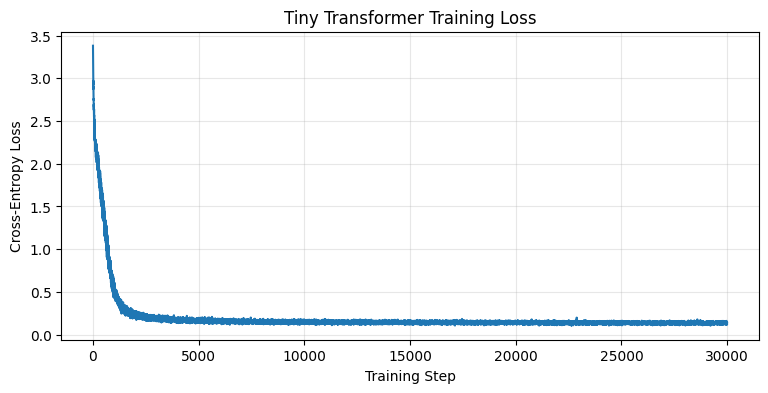

In [33]:
# ============================================================
# CELL 14F: VISUALIZE TRAINING LOSS
# ============================================================
# Purpose:
# Observe whether the model's prediction error decreases
# during training.
#
# A decreasing training loss suggests that the model is
# learning patterns in the training corpus.
#
# However, lower training loss does NOT guarantee that
# the model generalizes to unseen text.
# ============================================================

plt.figure(figsize=(9, 4))
plt.plot(loss_history)
plt.xlabel("Training Step")
plt.ylabel("Cross-Entropy Loss")
plt.title("Tiny Transformer Training Loss")
plt.grid(alpha=0.3)
plt.show()

In [34]:
# ============================================================
# CELL 14G: EVALUATE THE TRAINED MODEL
# ============================================================
# IMPORTANT: Repeated training sentences also appear in validation.
# This validation score does not measure genuine generalization.
# Purpose:
# Training loss measures performance on training examples.
#
# Validation loss measures performance on held-out examples.
#
# Comparing them helps us detect possible overfitting.
#
# Our synthetic corpus repeats many sentences, so the
# validation set is not truly independent in content.
#
# For meaningful generalization evaluation, use a corpus
# with genuinely distinct training and validation examples.
# ============================================================

@torch.no_grad()
def evaluate(model, source, batches=20):
    """Estimate average loss over randomly sampled batches."""
    model.eval()
    losses = []

    for _ in range(batches):
        x, y = get_batch(source)
        losses.append(calculate_loss(model(x), y).item())

    model.train()
    return sum(losses) / len(losses)

train_loss = evaluate(model, train_data)
val_loss = evaluate(model, val_data)

print("Training loss:", round(train_loss, 4))
print("Validation loss:", round(val_loss, 4))

Training loss: 0.134
Validation loss: 0.1396


# PART 8: GENERATE TEXT

In [35]:
# ============================================================
# CELL 14H: COMPARE TEXT BEFORE AND AFTER TRAINING
# ============================================================
# Purpose:
# Compare text from random weights with text from learned weights.
# The two outputs use the same prompt and sampling settings.
# ============================================================

AFTER_TRAINING = generate_text(model, "students ", max_new_tokens=60, temperature=0.7)
print("BEFORE TRAINING:", repr(BEFORE_TRAINING))
print("AFTER TRAINING: ", repr(AFTER_TRAINING))

BEFORE TRAINING: 'students e\nuwi\nv joott\nbirgoll.ollmwy jl\nyumblljhblilh.gdtwlfexgmlxlp'
AFTER TRAINING:  'students learn python programming.\nstudents develop artificial intell'
